# What Drives Bike Rentals in Washington DC?
### An exploratory data analysis of 2 years of Capital Bikeshare data

**The business question.** A bike-sharing company has to have bikes in the right place at the right time, and plan maintenance when demand is low. To do that, it needs to understand **when** and **why** people rent bikes.

**The data.** 17,379 hourly records from Capital Bikeshare, Washington DC, for 2011–2012, with weather data. Source: the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) (CC BY 4.0, citation in [README.md](README.md)).

**Questions**
1. Is the data trustworthy? What needs fixing?
2. How did demand change over the two years?
3. How do seasons and months affect rentals?
4. How does demand change through the day, and is a workday different from a day off?
5. Do casual riders and registered members behave differently?
6. How much does weather matter?

The summary of findings is in [README.md](README.md). This notebook shows the full analysis.

In [1]:
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from scipy import stats

sys.path.insert(0, "../13_visualisation")
import chart_style as cs

cs.apply()
pd.set_option("display.max_columns", 20)

raw = pd.read_csv("data/hour.csv", parse_dates=["dteday"])
print(raw.shape)
raw.head()

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# 1. Understand the data

The codes in the raw file (`season` 1–4, `weathersit` 1–4, temperatures divided by 41...) are explained in the dataset's [Readme.txt](data/Readme.txt). **Always read the data dictionary first, and then check it against the data.**

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

In [3]:
raw.describe().round(2)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.00,17379,17379.00,17379.0,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00
mean,8690.00,2012-01-02 04:08:34.552045,2.50,0.5,6.54,11.55,0.03,3.00,0.68,1.43,0.50,0.48,0.63,0.19,35.68,153.79,189.46
min,1.00,2011-01-01 00:00:00,1.00,0.0,1.00,0.00,0.00,0.00,0.00,1.00,0.02,0.00,0.00,0.00,0.00,0.00,1.00
25%,4345.50,2011-07-04 00:00:00,2.00,0.0,4.00,6.00,0.00,1.00,0.00,1.00,0.34,0.33,0.48,0.10,4.00,34.00,40.00
50%,8690.00,2012-01-02 00:00:00,3.00,1.0,7.00,12.00,0.00,3.00,1.00,1.00,0.50,0.48,0.63,0.19,17.00,115.00,142.00
75%,13034.50,2012-07-02 00:00:00,3.00,1.0,10.00,18.00,0.00,5.00,1.00,2.00,0.66,0.62,0.78,0.25,48.00,220.00,281.00
max,17379.00,2012-12-31 00:00:00,4.00,1.0,12.00,23.00,1.00,6.00,1.00,4.00,1.00,1.00,1.00,0.85,367.00,886.00,977.00
std,5017.03,NaN,1.11,0.5,3.44,6.91,0.17,2.01,0.47,0.64,0.19,0.17,0.19,0.12,49.31,151.36,181.39


## 1.1 Check the data dictionary: the season codes are mislabelled

The Readme says `season` 1 = spring, 2 = summer, 3 = fall, 4 = winter. Let's see which months each code covers:

In [4]:
raw.groupby("season")["mnth"].unique()

season
1      [1, 2, 3, 12]
2       [3, 4, 5, 6]
3       [6, 7, 8, 9]
4    [9, 10, 11, 12]
Name: mnth, dtype: object

**Season 1 covers December to March, which is winter, not spring.** The codes follow the astronomical seasons (season 1 runs from about 21 December to 20 March), so the labels in the Readme are shifted by one. If we trusted the Readme, every "spring" result in our analysis would really be about winter.

> 💡 **Lesson:** documentation is written by people and can be wrong. Verify it against the data.

## 1.2 Build a clean, readable table

In [5]:
df = pd.DataFrame({
    "datetime": raw["dteday"] + pd.to_timedelta(raw["hr"], unit="h"),
    "date": raw["dteday"],
    "year": raw["dteday"].dt.year,
    "month": raw["dteday"].dt.month,
    "hour": raw["hr"],
    "weekday": raw["dteday"].dt.day_name(),
    "season": raw["season"].map({1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}),
    "holiday": raw["holiday"].astype(bool),
    "workingday": raw["workingday"].astype(bool),
    "weather": raw["weathersit"].map({1: "Clear", 2: "Mist / cloudy", 3: "Light rain / snow", 4: "Heavy rain / snow"}),
    "temp_c": (raw["temp"] * 41).round(1),            # the Readme: values were divided by 41
    "feels_like_c": (raw["atemp"] * 50).round(1),     # divided by 50
    "humidity": (raw["hum"] * 100).round(0),          # divided by 100
    "windspeed": (raw["windspeed"] * 67).round(1),    # divided by 67
    "casual": raw["casual"],
    "registered": raw["registered"],
    "rides": raw["cnt"],
})
df.head()

,datetime,date,year,month,hour,weekday,season,holiday,workingday,weather,temp_c,feels_like_c,humidity,windspeed,casual,registered,rides
0,2011-01-01 00:00:00,2011-01-01,2011,1,0,Saturday,Winter,False,False,Clear,9.8,14.4,81.0,0.0,3,13,16
1,2011-01-01 01:00:00,2011-01-01,2011,1,1,Saturday,Winter,False,False,Clear,9.0,13.6,80.0,0.0,8,32,40
2,2011-01-01 02:00:00,2011-01-01,2011,1,2,Saturday,Winter,False,False,Clear,9.0,13.6,80.0,0.0,5,27,32
3,2011-01-01 03:00:00,2011-01-01,2011,1,3,Saturday,Winter,False,False,Clear,9.8,14.4,75.0,0.0,3,10,13
4,2011-01-01 04:00:00,2011-01-01,2011,1,4,Saturday,Winter,False,False,Clear,9.8,14.4,75.0,0.0,0,1,1


# 2. Data quality checks

In [6]:
print("missing values:", df.isna().sum().sum())
print("duplicate rows: ", df.duplicated().sum())
print("rides == casual + registered in every row:", (df["rides"] == df["casual"] + df["registered"]).all())

missing values: 0
duplicate rows:  0
rides == casual + registered in every row: True


## 2.1 Missing hours

731 days × 24 hours should give 17,544 rows, but we have 17,379. Which hours are missing?

In [7]:
hours_per_day = df.groupby("date").size()
print(f"expected {len(hours_per_day) * 24:,} rows, found {len(df):,}: {len(hours_per_day) * 24 - len(df)} hours missing")
short_days = hours_per_day[hours_per_day < 23]
short_days.rename("hours recorded").to_frame()

expected 17,544 rows, found 17,379: 165 hours missing


,hours recorded
date,
2011-01-03,22
2011-01-11,22
2011-01-12,22
2011-01-18,12
2011-01-26,16
2011-01-27,8
2011-02-11,22
2011-02-22,18
2011-02-28,22


Most of these are short gaps in early 2011 (very quiet night hours with zero rentals may simply not have been recorded). But two clusters match **real events** in Washington DC:

| Dates | Event |
|-------|-------|
| 27–28 Aug 2011 | **Hurricane Irene** |
| 29–30 Oct 2012 | **Hurricane Sandy**: on 29 October only 1 hour (22 rides) was recorded |

These are real gaps, not errors. We keep them, but we'll remember them when reading trends, and a forecasting model should treat them as exceptional.

## 2.2 Impossible values

In [8]:
df[df["humidity"] == 0][["datetime", "humidity", "temp_c", "weather"]].head()

,datetime,humidity,temp_c,weather
1551,2011-03-10 00:00:00,0.0,13.9,Light rain / snow
1552,2011-03-10 01:00:00,0.0,13.9,Light rain / snow
1553,2011-03-10 02:00:00,0.0,13.9,Light rain / snow
1554,2011-03-10 05:00:00,0.0,14.8,Light rain / snow
1555,2011-03-10 06:00:00,0.0,14.8,Light rain / snow


In [9]:
print("hours with 0% humidity:", (df["humidity"] == 0).sum(), "on", df.loc[df["humidity"] == 0, "date"].dt.date.unique())
print("lowest humidity on any other day:", df.loc[df["humidity"] > 0, "humidity"].min(), "%")

hours with 0% humidity: 22 on [datetime.date(2011, 3, 10)]
lowest humidity on any other day: 8.0 %


Humidity in Washington DC never reaches 0% (the next-lowest reading is 8%), and on 10 March 2011 it reads 0% all day, alongside rain. That's a **sensor failure**. We mark those values as missing so they can't distort any analysis of humidity.

In [10]:
df.loc[df["humidity"] == 0, "humidity"] = np.nan
df.to_csv("data/bike_hourly_clean.csv", index=False)   # saved for the machine learning topic

daily = df.groupby("date").agg(
    rides=("rides", "sum"), casual=("casual", "sum"), registered=("registered", "sum"),
    workingday=("workingday", "first"), holiday=("holiday", "first"), season=("season", "first"),
    year=("year", "first"), month=("month", "first"), weekday=("weekday", "first"),
    temp_c=("temp_c", "mean"), humidity=("humidity", "mean"), windspeed=("windspeed", "mean"),
    weather=("weather", lambda w: w.mode()[0]),        # the day's MOST COMMON weather
)
daily["weather"] = daily["weather"].replace({"Light rain / snow": "Rain / snow", "Heavy rain / snow": "Rain / snow"})
print(daily.shape)
daily.head(3)

(731, 13)


,rides,casual,registered,workingday,holiday,season,year,month,weekday,temp_c,humidity,windspeed,weather
date,,,,,,,,,,,,,
2011-01-01,985,331,654,False,False,Winter,2011,1,Saturday,14.100000,80.583333,10.750000,Clear
2011-01-02,801,131,670,False,False,Winter,2011,1,Sunday,14.908696,69.608696,16.652174,Mist / cloudy
2011-01-03,1349,120,1229,True,False,Winter,2011,1,Monday,8.050000,43.727273,16.636364,Clear


# 3. How did demand change over two years?

In [11]:
yearly = daily.groupby("year")["rides"].sum()
growth = yearly[2012] / yearly[2011] - 1
print(f"2011: {yearly[2011]:,} rides\n2012: {yearly[2012]:,} rides\ngrowth: {growth:.0%}")

2011: 1,243,103 rides
2012: 2,049,576 rides
growth: 65%


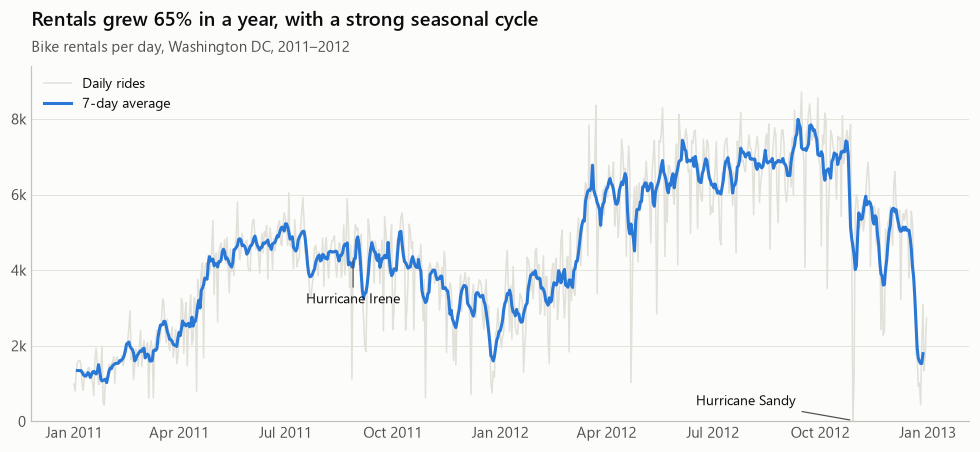

In [12]:
rolling = daily["rides"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(daily.index, daily["rides"], color=cs.GRID, linewidth=1, label="Daily rides")
ax.plot(rolling.index, rolling, color=cs.PRIMARY, linewidth=2, label="7-day average")
for date, label, offset in [("2011-08-28", "Hurricane Irene", (0, -30)), ("2012-10-29", "Hurricane Sandy", (-70, 10))]:
    ts = pd.Timestamp(date)
    ax.annotate(label, (ts, daily.loc[ts, "rides"]), xytext=offset, textcoords="offset points",
                ha="center", fontsize=9, color=cs.INK,
                arrowprops={"arrowstyle": "-", "color": cs.INK_SECONDARY, "linewidth": 0.8})
ax.set_ylim(0, daily["rides"].max() * 1.08)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}k" if v else "0"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
cs.only_grid(ax, "y")
ax.legend(loc="upper left")
cs.title(ax, f"Rentals grew {growth:.0%} in a year, with a strong seasonal cycle", "Bike rentals per day, Washington DC, 2011–2012")
fig.savefig("images/daily_trend.png")
plt.show()

**Findings**
- Demand grew **65%** from 2011 to 2012. The system was expanding fast.
- There's a strong **yearly cycle**: high in summer, low in winter.
- The day-to-day line is very noisy. The 7-day average shows the trend.
- The two sharp drops are the hurricanes.

# 4. Seasons and months

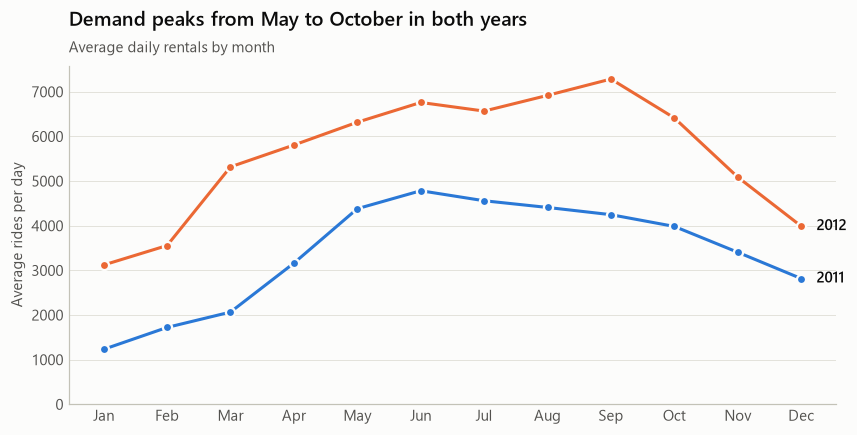

In [13]:
monthly = daily.groupby(["year", "month"])["rides"].mean().unstack(0)
month_names = pd.to_datetime([f"2012-{m}-01" for m in monthly.index]).strftime("%b")

fig, ax = plt.subplots(figsize=(9, 4))
for year, color in [(2011, cs.SLOTS[0]), (2012, cs.SLOTS[1])]:
    ax.plot(month_names, monthly[year], color=color, marker="o", markeredgecolor=cs.SURFACE, markeredgewidth=1.5)
    ax.annotate(str(year), (11, monthly[year].iloc[-1]), xytext=(10, 0), textcoords="offset points",
                va="center", fontweight="semibold", color=cs.INK)
ax.set_ylim(0)
ax.set_ylabel("Average rides per day")
cs.only_grid(ax, "y")
cs.title(ax, "Demand peaks from May to October in both years", "Average daily rentals by month")
plt.show()

In [14]:
season_order = ["Winter", "Spring", "Summer", "Fall"]
daily.groupby("season")["rides"].agg(["mean", "median", "count"]).reindex(season_order).round(0)

,mean,median,count
season,,,
Winter,2604.0,2209.0,181
Spring,4992.0,4942.0,184
Summer,5644.0,5354.0,188
Fall,4728.0,4634.0,178


**Findings**
- Both years follow the same shape: low in winter, rising through spring, and highest from about **May to October**.
- 2012 is higher than 2011 in **every month**, so the growth is across the board, not a one-off.
- **Winter** has roughly half the rentals of summer. That's the best time for maintenance.

# 5. When during the day? Workdays vs days off

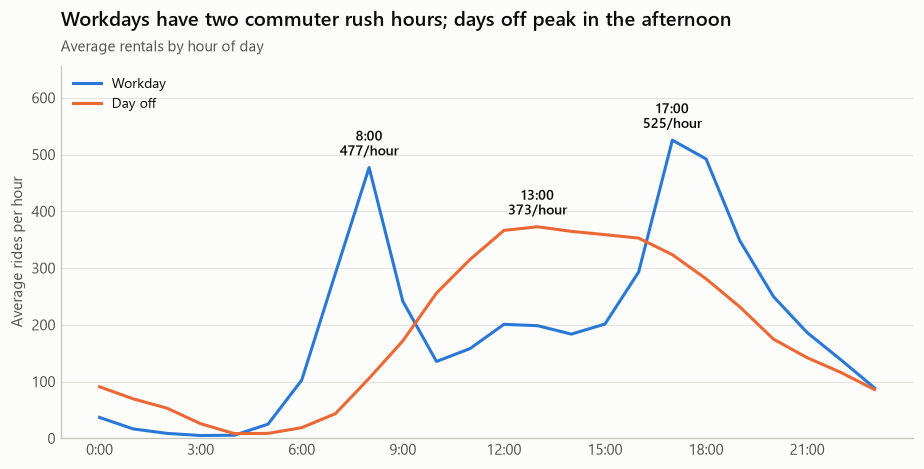

In [15]:
profile = df.groupby(["workingday", "hour"])["rides"].mean().unstack(0)
profile.columns = ["Day off", "Workday"]

fig, ax = plt.subplots(figsize=(10, 4.4))
for name, color in [("Workday", cs.SLOTS[0]), ("Day off", cs.SLOTS[1])]:
    ax.plot(profile.index, profile[name], color=color, label=name)
work_peaks = [8, 17]
for hour in work_peaks:
    ax.annotate(f"{hour}:00\n{profile.loc[hour, 'Workday']:.0f}/hour", (hour, profile.loc[hour, "Workday"]),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, fontweight="semibold")
peak_off = profile["Day off"].idxmax()
ax.annotate(f"{peak_off}:00\n{profile.loc[peak_off, 'Day off']:.0f}/hour", (peak_off, profile.loc[peak_off, "Day off"]),
            xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, fontweight="semibold")
ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
ax.set_ylim(0, profile.values.max() * 1.25)
ax.set_ylabel("Average rides per hour")
cs.only_grid(ax, "y")
ax.legend(loc="upper left")
cs.title(ax, "Workdays have two commuter rush hours; days off peak in the afternoon",
         "Average rentals by hour of day")
fig.savefig("images/hourly_profile.png")
plt.show()

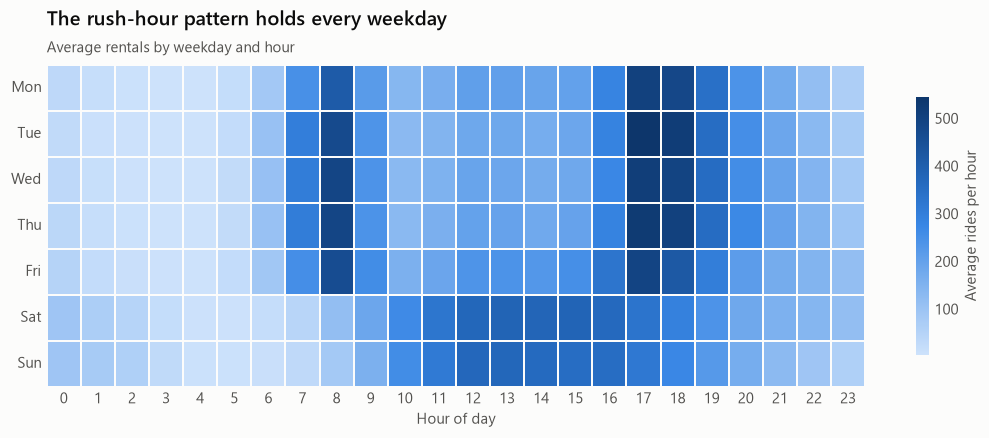

In [16]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
grid = df.pivot_table(index="weekday", columns="hour", values="rides", aggfunc="mean").reindex(days)

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(grid, cmap=cs.BLUES, linewidths=1, linecolor=cs.SURFACE, ax=ax,
            cbar_kws={"label": "Average rides per hour", "shrink": 0.8})
ax.set(xlabel="Hour of day", ylabel="")
ax.set_yticklabels([d[:3] for d in days], rotation=0)
ax.grid(False)
cs.title(ax, "The rush-hour pattern holds every weekday", "Average rentals by weekday and hour")
fig.savefig("images/weekday_hour_heatmap.png")
plt.show()

**Findings**
- On **workdays**, demand has two sharp peaks: **8:00** (about 480 rides an hour) and **17:00–18:00** (about 525). That's commuters going to and from work.
- On **days off**, there's one broad hump from about 11:00 to 17:00. That's leisure riding.
- The heatmap shows the commuter pattern is the same on all five weekdays, and Saturday and Sunday look alike.
- **Action:** move bikes to residential areas before 8:00 and to office areas before 17:00 on workdays. Night hours (0:00–5:00) are nearly empty, which makes them the best time to rebalance and repair bikes.

# 6. Casual riders vs registered members

In [17]:
share = df["registered"].sum() / df["rides"].sum()
print(f"Registered members take {share:.0%} of all rides")

by_daytype = daily.groupby("workingday")[["registered", "casual", "rides"]].mean().round(0)
by_daytype.index = ["Day off", "Workday"]
by_daytype

Registered members take 81% of all rides


,registered,casual,rides
Day off,2959.0,1371.0,4330.0
Workday,3978.0,607.0,4585.0


In [18]:
# Statistical check (topic 14): do workdays and days off differ in TOTAL rides?
work = daily.loc[daily["workingday"], "rides"]
off = daily.loc[~daily["workingday"], "rides"]
print(f"total rides:  p = {stats.mannwhitneyu(work, off).pvalue:.2f}")
print(f"casual rides: p = {stats.mannwhitneyu(daily.loc[daily['workingday'], 'casual'], daily.loc[~daily['workingday'], 'casual']).pvalue:.1g}")

total rides:  p = 0.12
casual rides: p = 4e-29


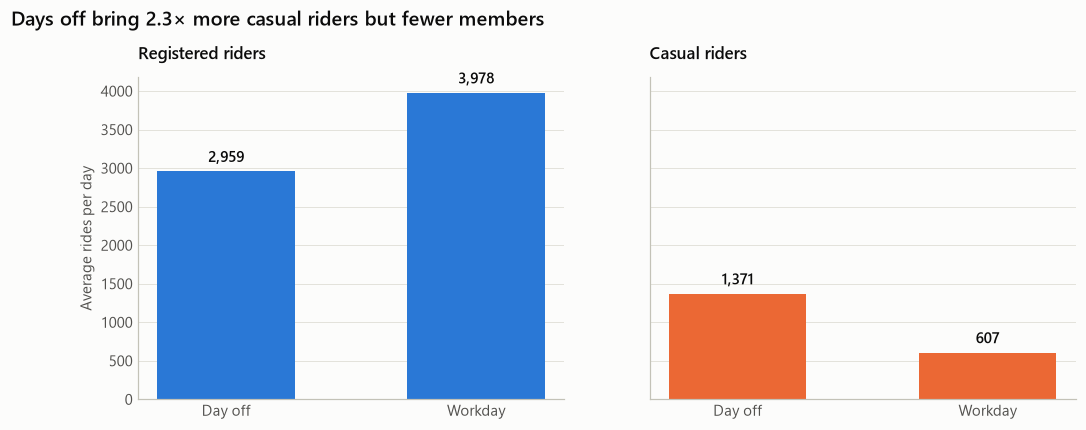

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, user, color in [(axes[0], "registered", cs.SLOTS[0]), (axes[1], "casual", cs.SLOTS[1])]:
    values = by_daytype[user]
    bars = ax.bar(values.index, values.values, color=color, width=0.55)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values.values], padding=4, fontweight="semibold")
    ax.set_title(f"{user.title()} riders", fontsize=11)
    cs.only_grid(ax, "y")
axes[0].set_ylabel("Average rides per day")
fig.suptitle("Days off bring 2.3× more casual riders but fewer members", x=0.02, ha="left",
             fontsize=13, fontweight="semibold", y=1.04)
plt.show()

**Findings**
- Workdays and days off have a similar **total** (4,585 vs 4,330 a day; the difference isn't significant, p = 0.12).
- But the total **hides two different groups**. On days off, casual riders more than double (607 → 1,371 a day) and registered members drop (3,978 → 2,959).
- Registered members (81% of rides) are mainly **commuters**. Casual riders are mainly **leisure** users.
- **Action:** weekend promotions and membership offers aimed at casual riders. Converting them is the clearest growth opportunity.

> 💡 **Lesson:** always break totals down by meaningful groups. An average can hide opposite behaviours.

# 7. How much does weather matter?

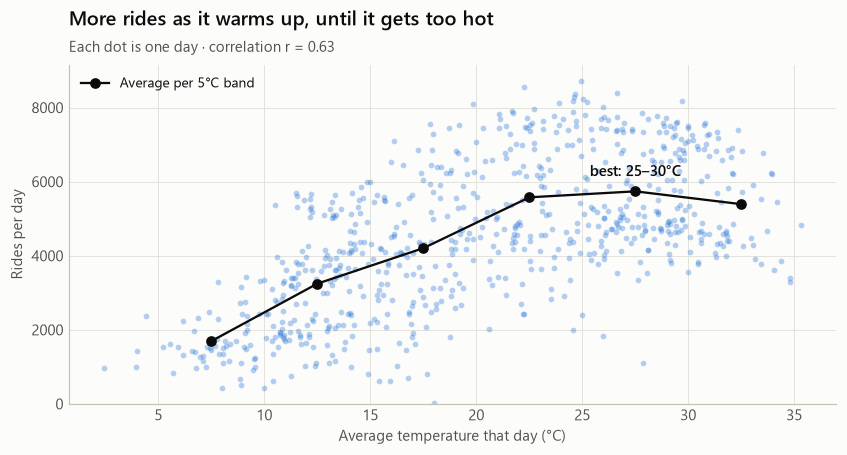

In [20]:
bins = list(range(0, 41, 5))
daily["temp_band"] = pd.cut(daily["temp_c"], bins=bins, labels=[f"{b}–{b + 5}°C" for b in bins[:-1]])
by_temp = daily.groupby("temp_band", observed=True)["rides"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(daily["temp_c"], daily["rides"], s=14, color=cs.PRIMARY, alpha=0.35, linewidth=0)
days_per_band = daily.groupby("temp_band", observed=True).size()
by_temp = by_temp[days_per_band >= 10]          # skip bands with too few days to trust (35–40°C has 1)
centres = [int(str(b).split("–")[0]) + 2.5 for b in by_temp.index]
ax.plot(centres, by_temp.values, color=cs.INK, marker="o", markersize=6, linewidth=1.5, label="Average per 5°C band")
best = by_temp.idxmax()
ax.annotate(f"best: {best}", (centres[list(by_temp.index).index(best)], by_temp.max()), xytext=(0, 10),
            textcoords="offset points", ha="center", fontweight="semibold")
ax.set(xlabel="Average temperature that day (°C)", ylabel="Rides per day")
ax.set_ylim(0)
ax.legend(loc="upper left")
r = daily["temp_c"].corr(daily["rides"])
cs.title(ax, "More rides as it warms up, until it gets too hot", f"Each dot is one day · correlation r = {r:.2f}")
fig.savefig("images/temperature.png")
plt.show()

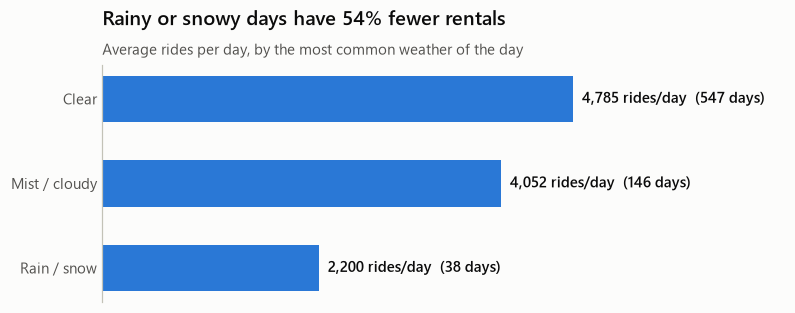

Kruskal-Wallis across weather types: p = 3e-15


In [21]:
weather_order = ["Clear", "Mist / cloudy", "Rain / snow"]
by_weather = daily.groupby("weather")["rides"].agg(["mean", "count"]).reindex(weather_order)

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(weather_order[::-1], by_weather["mean"][::-1], color=cs.PRIMARY, height=0.55)
ax.bar_label(bars, labels=[f"{v:,.0f} rides/day  ({n} days)" for v, n in zip(by_weather["mean"][::-1], by_weather["count"][::-1])],
             padding=6, fontweight="semibold")
ax.xaxis.set_visible(False)
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.set_xlim(0, by_weather["mean"].max() * 1.45)
drop = 1 - by_weather.loc["Rain / snow", "mean"] / by_weather.loc["Clear", "mean"]
cs.title(ax, f"Rainy or snowy days have {drop:.0%} fewer rentals", "Average rides per day, by the most common weather of the day")
plt.show()

print("Kruskal-Wallis across weather types: p =", f"{stats.kruskal(*[g['rides'] for _, g in daily.groupby('weather')]).pvalue:.1g}")

### How you define a category changes the answer

What counts as a "rainy day"? Above, it's a day where rain was the **most common** weather. What if one rainy hour were enough?

In [22]:
any_rain = df.groupby("date")["weather"].agg(lambda w: w.str.contains("rain").any())
compare = pd.DataFrame({
    "rainy days": [(daily["weather"] == "Rain / snow").sum(), any_rain.sum()],
    "drop in rides vs other days": [
        1 - daily.loc[daily["weather"] == "Rain / snow", "rides"].mean() / daily.loc[daily["weather"] != "Rain / snow", "rides"].mean(),
        1 - daily.loc[any_rain, "rides"].mean() / daily.loc[~any_rain, "rides"].mean(),
    ],
}, index=["rain is the main weather", "at least one rainy hour"])
compare.style.format({"drop in rides vs other days": "{:.0%}"})

,rainy days,drop in rides vs other days
rain is the main weather,38,52%
at least one rainy hour,300,17%


With the loose definition, **300 of 731 days** count as rainy (a 3 am drizzle is enough), so the effect looks much smaller. Neither number is "wrong", but they answer different questions. **Always state your definitions**, and pick the one that matches the business question. (Here: "how much does a rainy day hurt demand?")

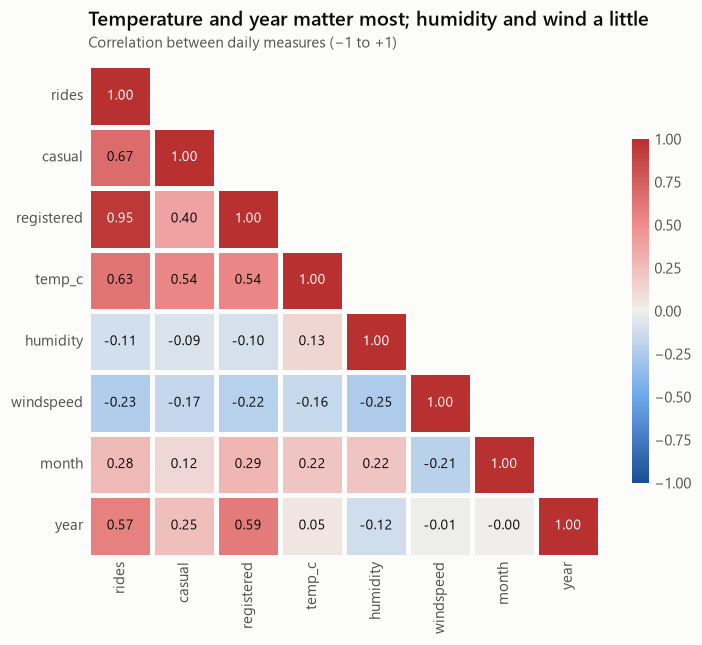

In [23]:
numeric = daily[["rides", "casual", "registered", "temp_c", "humidity", "windspeed", "month", "year"]]
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(7.5, 5.8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=cs.DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            linewidths=2, linecolor=cs.SURFACE, cbar_kws={"shrink": 0.7}, annot_kws={"fontsize": 9}, ax=ax)
ax.grid(False)
for text in ax.texts:   # white text only on the darkest cells, black elsewhere
    text.set_color("#ffffff" if abs(float(text.get_text())) >= 0.75 else cs.INK)
cs.title(ax, "Temperature and year matter most; humidity and wind a little",
         "Correlation between daily measures (−1 to +1)")
plt.show()

**Findings**
- **Temperature** has the strongest link to demand (r = 0.63). Rentals rise steadily up to **25–30 °C**, then dip slightly on the hottest days.
- Days with **rain or snow** see about **54% fewer** rentals. The difference between weather types is highly significant.
- Humidity and wind have weaker, negative effects.
- **Year** is strongly correlated too. That's the growth trend, which any forecast must include.
- **Action:** use the weather forecast to plan staff and bike supply; rainy days are ideal for maintenance work.

> ⚠️ Correlation isn't causation: warm days are also summer days, with longer daylight and holidays. Temperature, season and month overlap, which is why topic 16 uses a model that considers them together.

# 8. Holidays

In [24]:
holiday_effect = pd.Series({
    "Workday (not a holiday)": daily.loc[daily["workingday"], "rides"].mean(),
    "Public holiday": daily.loc[daily["holiday"], "rides"].mean(),
    "Weekend": daily.loc[~daily["workingday"] & ~daily["holiday"], "rides"].mean(),
}).round(0)
print(holiday_effect.to_string())
print("\nnumber of holidays:", daily["holiday"].sum())

Workday (not a holiday)    4585.0
Public holiday             3735.0
Weekend                    4390.0

number of holidays: 21


Public holidays average **fewer** rides than both workdays and weekends: commuters stay home, but leisure riders don't fully replace them. With only 21 holidays in the data, treat this as a hint, not a firm conclusion.

# 9. Summary

| # | Question | Answer |
|---|----------|--------|
| 1 | Is the data trustworthy? | Mostly. The season labels in the docs are wrong, 165 hours are missing (two hurricanes), and one day has a broken humidity sensor |
| 2 | Trend | **+65%** from 2011 to 2012, growing in every month |
| 3 | Seasons | Peak May–October; winter has about half the summer demand |
| 4 | Time of day | Workdays: commuter peaks at **8:00 and 17:00–18:00**. Days off: one afternoon peak |
| 5 | User groups | Members = 81% of rides, mostly commuters. Casual riders **2.3×** more active on days off |
| 6 | Weather | Temperature is the strongest driver (best at 25–30 °C). Rainy days have **54%** fewer rentals |

### Recommendations
1. **Rebalance bikes before the rush hours**: residential areas before 8:00, business areas before 17:00 on workdays.
2. **Schedule maintenance** at night (0:00–5:00), on rainy days, and in winter, when demand is lowest.
3. **Target casual weekend riders** with membership offers. They're the biggest untapped group.
4. **Build a demand forecast** using hour, workday, temperature, weather and the growth trend. That's exactly what topic 16 does.

### Limitations
- Only two years of data from one city, so the growth rate may not continue.
- Weather is recorded for the city as a whole, not for each station.
- No station-level data, so we can't say *where* bikes are needed, only *when*.
- Holidays and extreme weather are rare in the data, so conclusions about them are weaker.